In [2]:
import sys
!{sys.executable} -m pip install xgboost


Defaulting to user installation because normal site-packages is not writeable
  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)


In [ ]:
##XGBoost  Extreme gradient boost
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import(
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

from xgboost import XGBClassifier

In [5]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
df.shape

(7043, 21)

In [9]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df['TotalCharges'].isnull().sum()

np.int64(0)

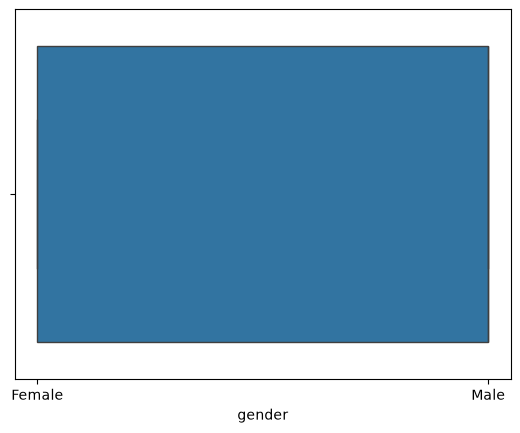

In [12]:
sns.boxplot(x=df['gender'])
plt.show()

In [13]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [17]:
# Correct syntax using a dictionary inside .map()
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})


In [18]:
df['Churn'].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [35]:
# 1. Define X by dropping the target column
X = df.drop(columns=['Churn']) 

# Pass a list containing both 'object' and 'str'
categorical_columns = X.select_dtypes(include=['object', 'str']).columns

# View the result
print("Categorical Columns:", list(categorical_columns))



Categorical Columns: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges']


In [31]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [32]:
# Count how many columns belong to each type
print("--- Column Type Counts ---")
print(df.dtypes.value_counts())

# List the specific columns
categorical_cols = df.select_dtypes(include=['object', 'str']).columns
numerical_cols = df.select_dtypes(include=['number']).columns

print("\n--- Categorical Columns ---")
print(list(categorical_cols))

print("\n--- Numerical Columns ---")
print(list(numerical_cols))


--- Column Type Counts ---
str        17
int64       3
float64     1
Name: count, dtype: int64

--- Categorical Columns ---
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges']

--- Numerical Columns ---
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'Churn']


In [45]:
# 1. Force 'TotalCharges' to be a float number (turns hidden blank text spaces into NaN)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())
df['TotalCharges'].isnull().sum()

np.int64(0)

In [40]:
df['TotalCharges'].unique()



array([  29.85, 1889.5 ,  108.15, ...,  346.45,  306.6 , 6844.5 ],
      shape=(6531,))

In [41]:
df['TotalCharges'].value_counts()

TotalCharges
20.200      11
1397.475    11
19.750       9
19.900       8
20.050       8
            ..
1990.500     1
7362.900     1
346.450      1
306.600      1
6844.500     1
Name: count, Length: 6531, dtype: int64

In [42]:
df['TotalCharges']

0         29.85
1       1889.50
2        108.15
3       1840.75
4        151.65
         ...   
7038    1990.50
7039    7362.90
7040     346.45
7041     306.60
7042    6844.50
Name: TotalCharges, Length: 7043, dtype: float64

In [43]:
df['TotalCharges'].isna().sum()


np.int64(0)

In [44]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [47]:
df = df.drop(columns=['customerID'], errors='ignore')
print(df)

      gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0     Female              0     Yes         No       1           No   
1       Male              0      No         No      34          Yes   
2       Male              0      No         No       2          Yes   
3       Male              0      No         No      45           No   
4     Female              0      No         No       2          Yes   
...      ...            ...     ...        ...     ...          ...   
7038    Male              0     Yes        Yes      24          Yes   
7039  Female              0     Yes        Yes      72          Yes   
7040  Female              0     Yes        Yes      11           No   
7041    Male              1     Yes         No       4          Yes   
7042    Male              0      No         No      66          Yes   

         MultipleLines InternetService OnlineSecurity OnlineBackup  \
0     No phone service             DSL             No          Yes   
1      

In [ ]:
binary_cols = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
for col in binary_cols:
    df[col] = df[col].map({'No': 0, 'Yes': 1})

In [49]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,1,0,1,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,Male,0,0,0,34,1,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.50,0
2,Male,0,0,0,2,1,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1
3,Male,0,0,0,45,0,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,0,0,2,1,No,Fiber optic,No,No,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1


(7043, 32)

In [65]:
multi_choice_cols = [
    'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 
    'Contract', 'PaymentMethod'
]

# This transforms multi-choice text into separate binary columns (0 or 1)
df = pd.get_dummies(df, columns=multi_choice_cols, drop_first=True, dtype=int)

KeyError: "None of [Index(['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',\n       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',\n       'Contract', 'PaymentMethod'],\n      dtype='str')] are in the [columns]"

In [51]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,Female,0,1,0,1,0,1,29.85,29.85,0,...,0,0,0,0,0,0,0,0,1,0
1,Male,0,0,0,34,1,0,56.95,1889.50,0,...,0,0,0,0,0,1,0,0,0,1
2,Male,0,0,0,2,1,1,53.85,108.15,1,...,0,0,0,0,0,0,0,0,0,1
3,Male,0,0,0,45,0,0,42.30,1840.75,0,...,1,0,0,0,0,1,0,0,0,0
4,Female,0,0,0,2,1,1,70.70,151.65,1,...,0,0,0,0,0,0,0,0,1,0


In [52]:
print("Remaining Categorical Columns:", len(df.select_dtypes(include=['object', 'str']).columns))
print("Total Numerical Columns Now Available:", len(df.select_dtypes(include=['number']).columns))


Remaining Categorical Columns: 1
Total Numerical Columns Now Available: 30


In [58]:
import pandas as pd

# Option 1: Create a basic sequential ID column (0, 1, 2, 3...)
df['Customer ID'] = range(len(df))

# Option 2: If you want it to look like custom customer numbers (e.g., 1001, 1002, 1003...)
# df['customerID'] = range(1001, 1001 + len(df))

# Optional: Move the new 'customerID' column to be the very first column
first_column = df.pop('Customer ID')
df.insert(0, 'Customer ID', first_column)

# Check the result
print(df[['Customer ID']].head())
df.head()



   Customer ID
0            0
1            1
2            2
3            3
4            4


,Customer ID,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,Female,0,1,0,1,0,1,29.85,...,0,0,0,0,0,0,0,0,1,0
1,1,1,Male,0,0,0,34,1,0,56.95,...,0,0,0,0,0,1,0,0,0,1
2,2,2,Male,0,0,0,2,1,1,53.85,...,0,0,0,0,0,0,0,0,0,1
3,3,3,Male,0,0,0,45,0,0,42.30,...,1,0,0,0,0,1,0,0,0,0
4,4,4,Female,0,0,0,2,1,1,70.70,...,0,0,0,0,0,0,0,0,1,0


In [60]:
df = df.drop(columns=['customerID'], errors = 'ignore')

In [61]:
df.head()


,Customer ID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,Female,0,1,0,1,0,1,29.85,29.85,...,0,0,0,0,0,0,0,0,1,0
1,1,Male,0,0,0,34,1,0,56.95,1889.50,...,0,0,0,0,0,1,0,0,0,1
2,2,Male,0,0,0,2,1,1,53.85,108.15,...,0,0,0,0,0,0,0,0,0,1
3,3,Male,0,0,0,45,0,0,42.30,1840.75,...,1,0,0,0,0,1,0,0,0,0
4,4,Female,0,0,0,2,1,1,70.70,151.65,...,0,0,0,0,0,0,0,0,1,0


In [62]:
df.shape

(7043, 32)

In [63]:
df.isnull().sum()

Customer ID                              0
gender                                   0
SeniorCitizen                            0
Partner                                  0
Dependents                               0
tenure                                   0
PhoneService                             0
PaperlessBilling                         0
MonthlyCharges                           0
TotalCharges                             0
Churn                                    0
MultipleLines_No phone service           0
MultipleLines_Yes                        0
InternetService_Fiber optic              0
InternetService_No                       0
OnlineSecurity_No internet service       0
OnlineSecurity_Yes                       0
OnlineBackup_No internet service         0
OnlineBackup_Yes                         0
DeviceProtection_No internet service     0
DeviceProtection_Yes                     0
TechSupport_No internet service          0
TechSupport_Yes                          0
StreamingTV

In [68]:
df= df.drop(columns = ['MultipleLines_No phone service',        
'InternetService_Fiber optic',              
'InternetService_No',                       
'OnlineSecurity_No internet service',    
'OnlineSecurity_Yes',                       
'OnlineBackup_No internet service ',        
'OnlineBackup_Yes        ',                 
'DeviceProtection_No internet service ',    
'DeviceProtection_Yes                 ',    
'TechSupport_No internet service    ',      
'TechSupport_Yes                ',          
'StreamingTV_No internet service  ',        
'StreamingTV_Yes'], errors = 'ignore')

In [69]:
df.shape

(7043, 26)

In [70]:
df.isnull().sum()

Customer ID                              0
gender                                   0
SeniorCitizen                            0
Partner                                  0
Dependents                               0
tenure                                   0
PhoneService                             0
PaperlessBilling                         0
MonthlyCharges                           0
TotalCharges                             0
Churn                                    0
MultipleLines_Yes                        0
OnlineBackup_No internet service         0
OnlineBackup_Yes                         0
DeviceProtection_No internet service     0
DeviceProtection_Yes                     0
TechSupport_No internet service          0
TechSupport_Yes                          0
StreamingTV_No internet service          0
StreamingMovies_No internet service      0
StreamingMovies_Yes                      0
Contract_One year                        0
Contract_Two year                        0
PaymentMeth

In [71]:
df = df.drop(columns = ['MultipleLines_Yes ',                       
'OnlineBackup_No internet service ',        
'OnlineBackup_Yes                   ',      
'DeviceProtection_No internet service    ', 
'DeviceProtection_Yes                 ',    
'TechSupport_No internet service    ',      
'TechSupport_Yes                   ',       
'StreamingTV_No internet service     ',     
'StreamingMovies_No internet service   ',   
'StreamingMovies_Yes                     ', 
'Contract_One year                        ',
'Contract_Two year                        ',
'PaymentMethod_Credit card (automatic)    ',
'PaymentMethod_Electronic check          ', 
'PaymentMethod_Mailed check             '], errors = 'ignore')

In [72]:
df.shape

(7043, 26)

In [73]:
df.isnull().sum()

Customer ID                              0
gender                                   0
SeniorCitizen                            0
Partner                                  0
Dependents                               0
tenure                                   0
PhoneService                             0
PaperlessBilling                         0
MonthlyCharges                           0
TotalCharges                             0
Churn                                    0
MultipleLines_Yes                        0
OnlineBackup_No internet service         0
OnlineBackup_Yes                         0
DeviceProtection_No internet service     0
DeviceProtection_Yes                     0
TechSupport_No internet service          0
TechSupport_Yes                          0
StreamingTV_No internet service          0
StreamingMovies_No internet service      0
StreamingMovies_Yes                      0
Contract_One year                        0
Contract_Two year                        0
PaymentMeth

In [74]:
print("Remaining Categorical Columns:", (df.select_dtypes(include=['object', 'str']).columns))
print("Total Numerical Columns Now Available:", (df.select_dtypes(include=['number']).columns))

Remaining Categorical Columns: Index(['gender'], dtype='str')
Total Numerical Columns Now Available: Index(['Customer ID', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges',
       'Churn', 'MultipleLines_Yes', 'OnlineBackup_No internet service',
       'OnlineBackup_Yes', 'DeviceProtection_No internet service',
       'DeviceProtection_Yes', 'TechSupport_No internet service',
       'TechSupport_Yes', 'StreamingTV_No internet service',
       'StreamingMovies_No internet service', 'StreamingMovies_Yes',
       'Contract_One year', 'Contract_Two year',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check'],
      dtype='str')


In [3]:
##XGBoost  Extreme gradient boost
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import(
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

from xgboost import XGBClassifier


df =pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

X = df.drop(columns=["Churn"])
y = df["Churn"]

# 2. Split the dataset into Training set (80%) and Testing set (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Initialize and train the XGBoost Model
model = XGBClassifier(
    use_label_encoder=False, eval_metric="logloss", random_state=42
)
model.fit(X_train, y_train)

# 4. Generate Predictions
y_pred = model.predict(X_test)  # Final 0 or 1 classification predictions
y_pred_proba = model.predict_proba(X_test)[
    :, 1
]  # Probability outputs for ROC AUC

# ==========================================
# 5. Calculate and Print Performance Metrics
# ==========================================
print("=== XGBoost Model Evaluation Metrics ===")

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy Score:    {accuracy:.4f}")

# Precision
precision = precision_score(y_test, y_pred)
print(f"Precision Score:   {precision:.4f}")

# Recall
recall = recall_score(y_test, y_pred)
print(f"Recall Score:      {recall:.4f}")

# F1-Score
f1 = f1_score(y_test, y_pred)
print(f"F1-Score:          {f1:.4f}")

# ROC AUC Score
roc_auc = roc_auc_score(y_test, y_pred_proba)
print(f"ROC AUC Score:      {roc_auc:.4f}")

# Confusion Matrix
print("\n=== Confusion Matrix ===")
print(confusion_matrix(y_test, y_pred))

# Classification Report
print("\n=== Detailed Classification Report ===")
print(classification_report(y_test, y_pred))

ValueError: Invalid classes inferred from unique values of `y`.  Expected: [0 1], got ['No' 'Yes']